# 01 · Exploring the KOFA reservations

**Goal:** understand the Cinematheque KOFA booking export well enough to turn it into seat-level data for SeatScore. That means the file's encoding, its seat number format, how cancellations are recorded, and what each hall's layout looks like.

**Source:** Korean Film Archive, *시네마테크KOFA 예매내역*, [data.go.kr dataset 15129428](https://www.data.go.kr/data/15129428/fileData.do). 613,406 bookings, Oct 2017 to Jul 2026, listed with no restrictions on use. The raw CSV lives in `data/raw/` and is not committed.

All loading and cleaning is in `pipeline/kofa.py` (tested in `pipeline/test_kofa.py`), so later notebooks reuse the same rules.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # make `pipeline` importable from notebooks/
from pipeline.kofa import ENCODING, RAW_CSV, inferred_rows, load_raw, seat_bookings

pd.set_option("display.width", 140)

# Chart style: recessive axes and grid, one sequential hue (blue ramp).
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE = "#2a78d6"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

## 1. Encoding

The file has no byte-order mark and is not valid UTF-8. It decodes cleanly as **CP949**, the Windows Korean code page that government exports often use. Reading it as UTF-8 fails on the very first byte.

In [2]:
raw_bytes = RAW_CSV.read_bytes()
for enc in ["utf-8", ENCODING]:
    try:
        raw_bytes.decode(enc)
        print(f"{enc:6} decodes the whole file")
    except UnicodeDecodeError as e:
        print(f"{enc:6} fails at byte {e.start}")
print(f"{len(raw_bytes) / 1e6:.1f} MB")

utf-8  fails at byte 0
cp949  decodes the whole file
33.6 MB


## 2. Load and first look

`load_raw` renames the Korean columns, parses the showtime, parses the seat text and labels each booking `kept`, `partial_cancel` or `full_cancel`.

In [3]:
df = load_raw()
print(f"{len(df):,} bookings · {df['title'].nunique():,} titles · {df.groupby(['hall', 'showtime']).ngroups:,} screenings")
df.head()

613,406 bookings · 2,684 titles · 5,040 screenings


,booking_id,hall,title,seats_raw,booked,cancelled,showtime,seats,n_seats_listed,status,seats_complete
0,10,hall1,명동에 밤이 오면,<NA>,1,1,2022-01-05 19:00:00,[],0,full_cancel,False
1,11,hall1,맨발로 왔다,<NA>,1,1,2022-01-05 16:00:00,[],0,full_cancel,False
2,12,hall1,명동에 밤이 오면,<NA>,1,1,2022-01-05 19:00:00,[],0,full_cancel,False
3,13,hall1,김약국의 딸들,<NA>,1,1,2022-01-06 16:00:00,[],0,full_cancel,False
4,14,hall1,명동에 밤이 오면,<NA>,1,1,2022-01-05 19:00:00,[],0,full_cancel,False


In [4]:
by_hall = df.groupby("hall", dropna=False).agg(bookings=("booking_id", "size"), tickets=("booked", "sum"), first=("showtime", "min"), last=("showtime", "max"))
by_hall

,bookings,tickets,first,last
hall,,,,
hall1,450170,545906,2017-10-12 16:30:00,2026-07-08 16:30:00
hall2,163108,207990,2017-10-17 15:00:00,2026-07-11 15:30:00
hall3,98,389,2018-07-07 14:30:00,2019-12-07 15:00:00
<NA>,30,30,2022-01-04 16:00:00,2022-02-25 19:00:00


Hall 1 and Hall 2 hold almost every booking. **Hall 3** (98 bookings) has no fixed seats, and 30 rows have no hall at all; both are dropped from the seat analysis.

## 3. Seat text format

Two styles appear, sometimes with several seats in one booking:

In [5]:
def style(s):
    if pd.isna(s) or not s.strip():
        return "empty"
    if "층" in s:
        return "(1층) H-16"
    return "O열 1번, several" if "," in s else "O열 1번"

styles = df.assign(style=df["seats_raw"].map(style), year=df["showtime"].dt.year)
styles.pivot_table(index="year", columns="style", values="booking_id", aggfunc="size", fill_value=0)

style,(1층) H-16,O열 1번,"O열 1번, several",empty
year,,,,
2017,0,10318,0,0
2018,0,92570,0,94
2019,0,96917,0,12
2020,0,28891,0,0
2021,0,40365,0,0
2022,1360,32973,1421,19941
2023,1394,37863,5178,30455
2024,1495,42722,5422,35320
2025,1484,37174,4959,28133


* `O열 1번` means row O (`열`), seat 1 (`번`). This is the main style in every year.
* `(1층) H-16` means floor 1, row H, seat 16. It only appears from 2022, and only for a few thousand bookings.
* Wheelchair spaces are written `휠체어석열 2번` or `휠체어석-1`; the pipeline uses row `W` for them.
* Every non-empty seat string parses with the pipeline's regular expression.

In [6]:
unparsed = df[df["seats_raw"].notna() & (df["seats_raw"].str.strip() != "") & (df["n_seats_listed"] == 0)]
print("unparsed seat strings:", len(unparsed))

unparsed seat strings: 0


## 4. Cancellations

The export's notes and the data agree on rules that change in 2022:

In [7]:
pattern = df.assign(
    period=np.where(df["showtime"] < "2022-01-01", "before 2022", "2022 on"),
    seats=np.select(
        [df["n_seats_listed"] == 0, df["n_seats_listed"] == df["booked"], df["n_seats_listed"] == df["cancelled"]],
        ["none listed", "one per ticket", "one per cancelled ticket"],
        "fewer than tickets",
    ),
)
pattern.pivot_table(index=["period", "status"], columns="seats", values="booking_id", aggfunc="size", fill_value=0)

seats                       fewer than tickets  none listed  one per cancelled ticket  one per ticket
period      status                                                                                   
2022 on     full_cancel                      0       137411                         0               0
            kept                             0            0                         0          202878
            partial_cancel                  66            0                      3884               0
before 2022 full_cancel                  15234            8                         0           53962
            kept                         44858           98                         0          155007

What this means for cleaning:

1. **Before 2022, cancelled bookings still list their seats.** Counting them would inflate popularity, so every booking with `cancelled > 0` is dropped.
2. **From 2022, full cancellations have no seat text, and partial ones list only the cancelled seats.** The seats that were kept are unknown, so partial cancellations are dropped too. There are only about 3,900 of them.
3. **Before 2022, multi-ticket bookings usually list only the first seat** (about 45,000 bookings, mostly pairs). Those are kept with `seats_complete = False`. The companion seats are missing, so seat counts before 2022 slightly under-count seats next to popular ones.

## 5. Seat-level table

`seat_bookings` keeps uncancelled Hall 1 and Hall 2 bookings, writes one row per seat, drops the rare duplicate (the same seat booked twice for one screening) and ranks bookings within each screening by booking id.

In [8]:
seats = seat_bookings(df)
print(f"{len(seats):,} booked seats · {seats.groupby(['hall', 'showtime']).ngroups:,} screenings")
print(f"order_in_screening: 0 = first booking for that screening")
seats.head()

440,083 booked seats · 5,012 screenings
order_in_screening: 0 = first booking for that screening


,booking_id,hall,title,showtime,party_size,seats_complete,row,number,seat_id,order_in_screening
0,15,hall1,맨발로 왔다,2022-01-05 16:00:00,1,True,N,11,N11,0
1,16,hall1,맨발로 왔다,2022-01-05 16:00:00,1,True,S,10,S10,1
2,19,hall1,맨발로 왔다,2022-01-05 16:00:00,1,True,B,1,B1,2
3,24,hall1,김약국의 딸들,2022-01-06 16:00:00,1,True,F,15,F15,0
4,25,hall1,맨발로 왔다,2022-01-05 16:00:00,1,True,E,1,E1,3


In [9]:
processed = Path("../processed")
processed.mkdir(exist_ok=True)
seats.to_csv(processed / "kofa_seat_bookings.csv.gz", index=False)
print("wrote", processed / "kofa_seat_bookings.csv.gz")

wrote ../processed/kofa_seat_bookings.csv.gz


## 6. Inferring the hall layouts

No public seat map exists, so each hall's layout comes from the seats people actually booked. A seat number seen fewer than 20 times over nine years is treated as noise or a since-removed seat, and listed separately. Wheelchair spaces (row `W`) are booked rarely, so they always count.

In [10]:
CAPACITY = {"hall1": 321, "hall2": 150}  # official seat counts
layouts = {}
for hall, capacity in CAPACITY.items():
    rows = inferred_rows(seats, hall)
    layouts[hall] = rows
    print(f"{hall}: {rows['seats'].sum()} seats inferred, official capacity {capacity}")
    display(rows)

hall1: 321 seats inferred, official capacity 321


,row,seats,first,last,bookings,rare_numbers
0,A,21,1,21,7824,NaN
1,B,21,1,21,10467,NaN
2,C,21,1,21,13836,NaN
3,D,21,1,21,17510,NaN
4,E,21,1,21,21146,NaN
5,F,21,1,21,23326,NaN
6,G,21,1,21,24090,NaN
7,H,21,1,21,25339,NaN
8,I,21,1,21,25284,NaN
9,J,21,1,21,29996,NaN


hall2: 150 seats inferred, official capacity 150


,row,seats,first,last,bookings,rare_numbers
0,A,12,1,12,3237,NaN
1,B,12,1,12,3677,NaN
2,C,12,1,12,5479,NaN
3,D,12,1,12,7526,NaN
4,E,12,1,12,9235,NaN
5,F,12,1,12,11008,NaN
6,G,12,1,12,12013,NaN
7,H,12,1,12,12195,NaN
8,I,12,1,12,12247,NaN
9,J,12,1,12,11360,NaN


Both totals match the official capacities exactly:

* **Hall 1 (321):** rows A–M and S have 21 seats each, row N has 17 (seat 8 is almost never booked, so it was probably removed), row O has 6, plus 4 wheelchair spaces.
* **Hall 2 (150):** rows A–K have 12 seats each, row L has 10 (seats 2–11), row M has 6 (seats 2 and 7–11), plus 2 wheelchair spaces.

**Open question:** where is Hall 1's row **S**? It is not in alphabetical sequence and is one of the most-booked rows. It may be a separate section, such as a raised rear row or a balcony. KOFA's booking page seat map should settle it before we build the SeatScore layout.

In [11]:
assert layouts["hall1"]["seats"].sum() == CAPACITY["hall1"]
assert layouts["hall2"]["seats"].sum() == CAPACITY["hall2"]

## 7. First look: how often each seat is booked

Share of screenings in which each seat was booked. Rows run front (A) to back, with Hall 1's row S at the bottom until its position is known. Wheelchair spaces are left out. One hue: darker means booked more often.

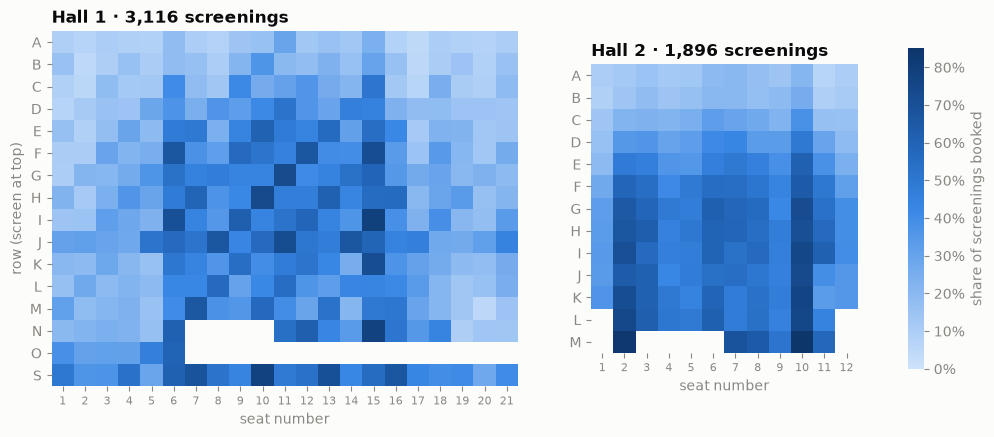

In [12]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list("blue", BLUE_RAMP)

def booking_rate_grid(hall):
    h = seats[(seats["hall"] == hall) & (seats["row"] != "W")]
    n_screenings = h.groupby("showtime").ngroups
    rate = h.groupby(["row", "number"]).size() / n_screenings
    common = rate[h.groupby(["row", "number"]).size() >= 20]
    grid = common.unstack("number").sort_index(key=lambda r: r.map(lambda x: (x == "S", x)))
    return grid, n_screenings

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [21, 12]})
for ax, hall in zip(axes, ["hall1", "hall2"]):
    grid, n = booking_rate_grid(hall)
    im = ax.imshow(grid.values, cmap=cmap, vmin=0, vmax=0.85, aspect="equal")
    ax.set_xticks(range(grid.shape[1]), grid.columns, fontsize=8)
    ax.set_yticks(range(grid.shape[0]), grid.index)
    ax.grid(False)
    ax.set_title(f"{'Hall 1' if hall == 'hall1' else 'Hall 2'} · {n:,} screenings", loc="left")
    ax.set_xlabel("seat number")
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_ylabel("row (screen at top)")
cbar = fig.colorbar(im, ax=axes, shrink=0.8, format=lambda x, _: f"{x:.0%}")
cbar.set_label("share of screenings booked")
cbar.outline.set_visible(False)
plt.show()

**What stands out:**

* **Hall 1 has a clear center block, seats 6–15,** that is booked far more than seats 1–5 and 16–21. That pattern suggests aisles after seat 5 and after seat 15, which the layout notebook should confirm.
* **Hall 1 row J and row S are booked almost all the way across.** Row J may sit behind a cross aisle with extra legroom.
* **The single most-booked seats sit at the edge of the center block** (Hall 1 seats 6, 10, 15; Hall 2 seats 2 and 10). If those are aisle seats, that is a first sign that real viewers value aisle access more than SeatScore's default weight of 0.

In [13]:
# Table view of the same numbers: the ten most-booked seats per hall.
for hall in ["hall1", "hall2"]:
    grid, _ = booking_rate_grid(hall)
    top = grid.stack().sort_values(ascending=False).head(10).rename("booking rate").map("{:.0%}".format)
    print(hall); print(top.to_string(), end="\n\n")

hall1
row  number
I    15        78%
S    10        78%
N    15        78%
H    10        73%
G    11        73%
J    11        72%
F    15        71%
K    15        71%
I    6         70%
S    13        70%

hall2
row  number
M    10        85%
     2         83%
K    10        76%
I    10        75%
L    10        75%
     2         74%
J    10        73%
G    10        72%
K    2         71%
H    10        70%



## 8. Was there seat distancing during COVID?

If every other seat was blocked in 2020–21, the share of booked seats with a booked neighbor in the same row would drop sharply. Pairs booked together still sit side by side, so it would not reach zero.

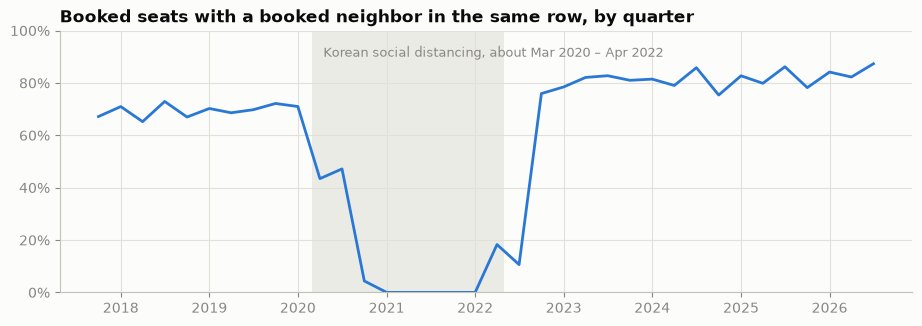

showtime,2017-10-01,2018-01-01,2018-04-01,2018-07-01,2018-10-01,2019-01-01,2019-04-01,2019-07-01,2019-10-01,2020-01-01,...,2024-04-01,2024-07-01,2024-10-01,2025-01-01,2025-04-01,2025-07-01,2025-10-01,2026-01-01,2026-04-01,2026-07-01
share with neighbor,67%,71%,65%,73%,67%,70%,69%,70%,72%,71%,...,79%,86%,75%,83%,80%,86%,78%,84%,82%,87%


In [14]:
s = seats[seats["row"] != "W"][["hall", "showtime", "row", "number"]]
neighbors = set(zip(s["hall"], s["showtime"], s["row"], s["number"]))
has_neighbor = [((h, t, r, n - 1) in neighbors) or ((h, t, r, n + 1) in neighbors) for h, t, r, n in zip(s["hall"], s["showtime"], s["row"], s["number"])]
adj = s.assign(has_neighbor=has_neighbor).set_index("showtime").groupby(pd.Grouper(freq="QS"))["has_neighbor"].mean()

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(adj.index, adj.values, color=BLUE, linewidth=2)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2022-04-30"), color=GRID, alpha=0.6, linewidth=0)
ax.text(pd.Timestamp("2020-04-15"), 0.9, "Korean social distancing, about Mar 2020 – Apr 2022", color=MUTED, fontsize=9)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Booked seats with a booked neighbor in the same row, by quarter", loc="left")
plt.show()
adj.map("{:.0%}".format).to_frame("share with neighbor").T

## Findings so far

1. **Encoding:** CP949, no BOM.
2. **Seat format:** `O열 1번` everywhere, plus `(1층) H-16` from 2022 and `휠체어석` for wheelchair spaces. All seat strings parse.
3. **Cancellations:** drop every booking with `cancelled > 0`. Before 2022 their seats are still listed, and from 2022 partial cancellations list only the cancelled seats.
4. **Missing companions:** before 2022, multi-ticket bookings mostly list just the first seat.
5. **Layouts:** inferred row by row, and both halls match their official capacities exactly (321 and 150).
6. **Distancing was enforced:** the share of booked seats with a booked neighbor fell from about 70% to almost 0% from late 2020 to early 2022, and was back above 75% by Q4 2022. Preference analysis should exclude **Apr 2020 – Sep 2022**, the window this chart shows, not just the official dates.
7. **Possible aisle preference:** the most-booked seats sit at the edges of the center block.

**Next notebook (`02_layouts`):** pin down row S, estimate each hall's screen size and row spacing, and write both halls into SeatScore's layout format. Then `03_preference` compares the geometry score with what people actually book, using `order_in_screening` for "which seats go first".